In [1]:
import random
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit

from ml.data_io import iter_signals_and_targets, iter_signals_only
from ml.features import add_epoch_drift, build_feature_df
from ml.model import fit_decoder_context, predict_with_decoder, train_xgboost, cross_validate_xgboost

In [2]:
@dataclass
class Config:
    bundle_dir: Path = Path("data")
    sf: int = 100  # sampling rate
    samples_per_epoch: int = 30 * 100  # 30s epochs
    stage_names: list[str] = field(default_factory=lambda: ["Wake", "N1", "N2", "N3", "REM"])
    # Feature params
    load_precomputed_features: bool = False
    bands: dict[str, tuple[float, float]] = field(
        default_factory=lambda: {
            "slow_delta": (0.5, 2),
            "delta": (2, 4),
            "theta": (4, 8),
            "alpha": (8, 12),
            "sigma": (12, 15),
            "beta": (15, 30),
        },
    )
    add_epoch_drift_window: int = 2
    add_epoch_drift_symmetric: bool = True
    # model params
    num_classes: int = 5
    eta: float = 0.03
    max_depth: int = 4
    subsample: float = 0.8
    colsample_bytree: float = 0.8
    num_boost_round: int = 500
    seed: int = 42
    smoothing_window: int = 1
    n_jobs: int = 4
    # decoding
    decoder: str = "hmm"  # options: "argmax", "smooth", "hmm"
    hmm_alpha: float = 1.0
    # cross-validation params
    cv_n_splits: int = 5
    # choose whether to create submission predictions
    create_submission: bool = False
    submission_name: str = "submission.csv"

In [3]:
config = Config(bundle_dir = Path("../data"))

In [4]:
raw_train_data = iter_signals_and_targets(config.bundle_dir, split="train")
raw_test_data = iter_signals_only(config.bundle_dir, split="test")
raw_train_data = iter_signals_and_targets(config.bundle_dir, split="train")
raw_test_data = iter_signals_only(config.bundle_dir, split="test")

In [5]:
df_train = build_feature_df(raw_train_data, with_labels=True, config=config)
df_train = add_epoch_drift(
    df_train,
    window=config.add_epoch_drift_window,
    symmetric=config.add_epoch_drift_symmetric,
)

In [6]:
X = df_train.drop(columns=["label", "identifier", "patient_id", "epoch_idx"])
y = df_train["label"]
groups = df_train["patient_id"].to_numpy()

In [28]:
X.shape

(7433, 26)

In [14]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=config.seed)
tr_idx, va_idx = next(gss.split(X, y, groups))

X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]


model = train_xgboost(X_tr, y_tr, config)
ctx = fit_decoder_context(
            y_tr,
            df_train.iloc[tr_idx],
            config,
        )

y_pred = predict_with_decoder(
    model,
    X_va,
    df_train.iloc[va_idx],
    config,
    ctx,
)
f1 = f1_score(y_va, y_pred, average="macro")

print(f"Macro-F1: {f1:.4f}")
print(
    classification_report(
        y_va,
        y_pred,
        target_names=config.stage_names,
        digits=3,
    ),
)

Macro-F1: 0.7649
              precision    recall  f1-score   support

        Wake      0.913     0.917     0.915       422
          N1      0.353     0.353     0.353        85
          N2      0.852     0.914     0.882       844
          N3      0.903     0.954     0.928       283
         REM      0.863     0.659     0.747       334

    accuracy                          0.853      1968
   macro avg      0.777     0.759     0.765      1968
weighted avg      0.853     0.853     0.850      1968



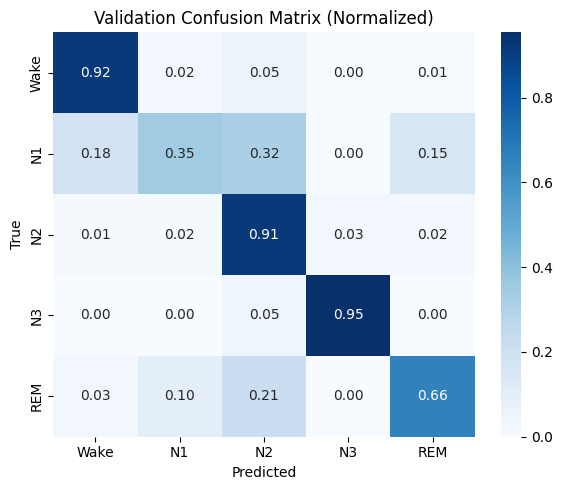

In [20]:
cm = confusion_matrix(y_va, y_pred, normalize="true")

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=config.stage_names,
    yticklabels=config.stage_names,
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Validation Confusion Matrix (Normalized)")
plt.tight_layout()

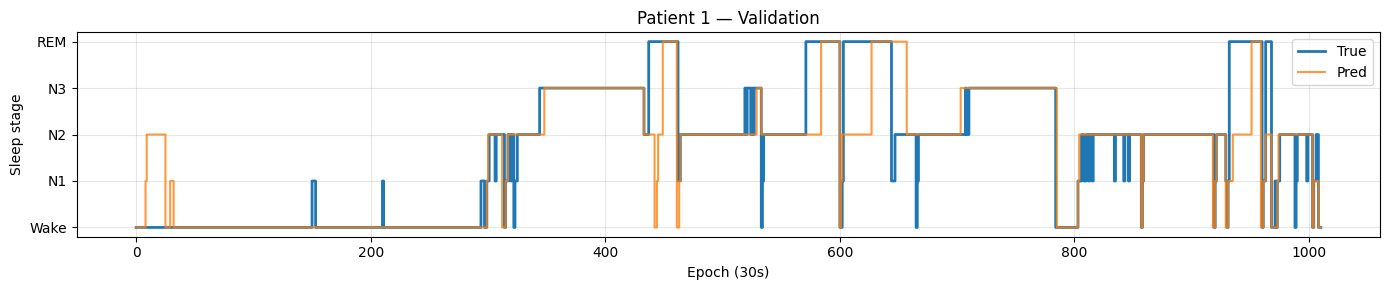

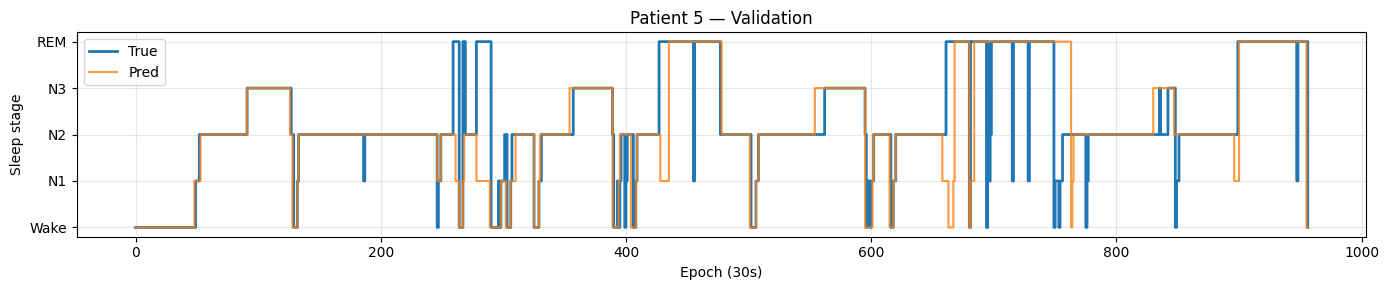

In [26]:
def plot_sleep_timeline_val(df, y_true, y_pred, patient_id, idx_subset):
    mask = (df["patient_id"] == patient_id) & df.index.isin(idx_subset)
    block = df.loc[mask].sort_values("epoch_idx")

    if len(block) == 0:
        return

    true = y_true.loc[block.index].values
    pred = y_pred[np.isin(idx_subset, block.index)]

    plt.figure(figsize=(14, 3))
    plt.plot(true, label="True", drawstyle="steps-post", linewidth=2)
    plt.plot(pred, label="Pred", drawstyle="steps-post", alpha=0.8)
    plt.yticks(
        ticks=[0, 1, 2, 3, 4],
        labels=["Wake", "N1", "N2", "N3", "REM"],
    )
    plt.xlabel("Epoch (30s)")
    plt.ylabel("Sleep stage")
    plt.title(f"Patient {patient_id} — Validation")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

# pick random validation patients
val_patients = df_train.iloc[va_idx]["patient_id"].unique().tolist()
for pid in random.sample(val_patients, k=min(3, len(val_patients))):
    plot_sleep_timeline_val(
        df_train,
        y_va,
        y_pred,
        patient_id=pid,
        idx_subset=va_idx,
    )


In [ ]:
cv_scores, model = cross_validate_xgboost(
        X_train,
        y_train,
        groups,
        df_train,
        config=config,
    )